# 03 — Data preparation and feature engineering

The working scenario is to score an application before final approval or pricing. Part D verifies the transformations on the development partition. Part E measures the effect of each preprocessing alternative using shared training folds.

## 1. Validate the source and reserve a holdout

Reuse the Part D 80:20 stratified split and seed. Keep holdout rows reserved for Part H. The cleaned file retains missing predictor values. The duplicate audit records whether any rows required removal.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if not (project_root / 'data' / 'processed' / 'loan_default_cleaned.csv').is_file():
    raise FileNotFoundError('Open this notebook from the project root or its notebooks folder.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_preparation import BASELINE_EXCLUSIONS, TrainingFoldPreprocessor, split_loan_data

df = pd.read_csv(project_root / 'data' / 'processed' / 'loan_default_cleaned.csv')

tables = project_root / 'outputs' / 'tables' / 'part_d'
figures = project_root / 'outputs' / 'figures' / 'part_d'
tables.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)

audit_path = project_root / 'outputs' / 'tables' / 'cleaning' / 'duplicate_audit.csv'
display(pd.read_csv(audit_path))
assert not df.duplicated().any()
assert df['id'].notna().all() and df['id'].is_unique
X_dev, X_holdout, y_dev, _ = split_loan_data(df)
assert X_dev.index.intersection(X_holdout.index).empty
assert len(X_dev) + len(X_holdout) == len(df)
assert y_dev.index.equals(X_dev.index)
assert set(X_dev.columns).isdisjoint(['status', *BASELINE_EXCLUSIONS])
print(f'Cleaned dataset: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Development: {len(X_dev):,} rows, {y_dev.mean():.2%} defaults | Reserved: {len(X_holdout):,} rows')
display(pd.Series(BASELINE_EXCLUSIONS, name='reason').to_frame())

Matplotlib is building the font cache; this may take a moment.


,check,count,decision
0,exact duplicate rows,0,Remove exact duplicates only if present
1,duplicate IDs,0,Investigate; never drop automatically by ID
2,duplicates excluding ID,0,Review only because different IDs may represen...


Cleaned dataset: 148,670 rows × 34 columns
Development: 118,936 rows, 24.64% defaults | Reserved: 29,734 rows


,reason
id,Application identifier.
year,Single recorded year; no time variation in thi...
gender,Sensitive attribute; excluded from the first m...
approv_in_adv,Records an approval decision; exclude until it...
rate_of_interest,Pricing information.
interest_rate_spread,Pricing information.
upfront_charges,Pricing information.
property_value,Recorded valuation timing unverified.
ltv,Requires an eligible valuation at scoring time.
dtir1,Recorded underwriting ratio timing unverified.


## 2. Separate fixed exclusions from training-only screening

Identifiers, the constant year, gender, approval and unverified pricing or underwriting fields are fixed exclusions. The remaining candidates undergo a statistical screen using only the labels passed to the transformer's fit method. A category or numeric missingness group is flagged when it and its complement each have at least 50 rows, its observed default rate is at least 98% or at most 2%, and the absolute default-rate gap is at least 50 percentage points. The cutoffs are conservative heuristics. A flagged group prompts a feature-level exclusion because its data provenance is unresolved. Groups smaller than the support threshold and other kinds of proxies can escape the screen.

The audit below describes the development set. Part E relearns the feature screen independently within each training fold. Earlier Part C EDA already inspected the entire file and informed the project's risk concerns. The later holdout is therefore an internal check, and an independent sample would give stronger evidence.

In [2]:
raw = TrainingFoldPreprocessor()
raw_matrix = raw.fit_transform(X_dev, y_dev)
logged = TrainingFoldPreprocessor(log_income=True)
log_matrix = logged.fit_transform(X_dev, y_dev)
assert raw.selected_features_ == logged.selected_features_
raw.screen_audit_.to_csv(tables / 'development_proxy_screen.csv', index=False)
display(raw.screen_audit_.query('flagged'))
print(f'{len(raw.selected_features_)} selected features out of {X_dev.shape[1]} candidates.')

,feature,group,support,default_rate,other_default_rate,flagged
34,credit_type,EQUI,12158,0.999918,0.160651,True
45,age,<missing>,156,1.000000,0.245454,True
48,submission_of_application,<missing>,156,1.000000,0.245454,True


20 selected features out of 23 candidates.


## 3. Test log income as a feature alternative

Compute the distribution from observed development incomes. Use the same observations in both plots, retain zeros and show missingness separately. The log compresses large values and leaves zero at zero, which can produce a left tail. A change in shape is evidence about the distribution. The matched CV comparison in Part E tests whether the transformation helps predictions.

,measure,value
0,observed,111581.000
1,missing,7355.000
2,zero,1033.000
3,observed_minimum,0.000
4,observed_median,5760.000
5,observed_maximum,578580.000
6,raw_skewness,18.110
7,log_skewness,-5.086


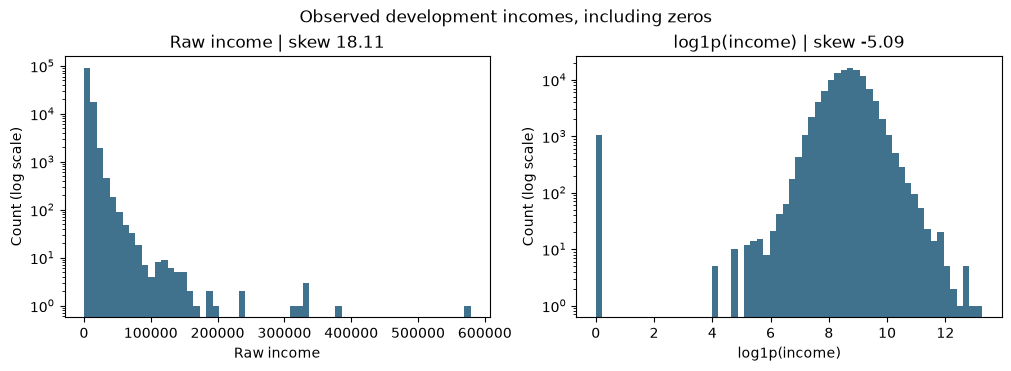

In [3]:
income = X_dev['income']
observed = income.dropna()
assert observed.ge(0).all()
logged_income = np.log1p(observed)
income_summary = pd.DataFrame({
    'measure': ['observed', 'missing', 'zero', 'observed_minimum', 'observed_median', 'observed_maximum',
                'raw_skewness', 'log_skewness'],
    'value': [len(observed), income.isna().sum(), observed.eq(0).sum(), observed.min(),
              observed.median(), observed.max(), observed.skew(), logged_income.skew()],
})
income_summary.to_csv(tables / 'income_profile.csv', index=False)
display(income_summary.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout='constrained')
for ax, values, title in zip(axes, [observed, logged_income], ['Raw income', 'log1p(income)']):
    ax.hist(values, bins=60, color='#40728E')
    ax.set(title=f'{title} | skew {values.skew():.2f}', xlabel=title, ylabel='Count (log scale)', yscale='log')
fig.suptitle('Observed development incomes, including zeros')
fig.savefig(figures / 'income_distributions.png', dpi=160)
plt.show()

## 4. Verify imputation, encoding and scaling

Numeric blanks take the training median and categoricals get a Missing level. One-hot encoding preserves categories without imposing an order and uses zeros for unseen levels. Standardisation puts numeric fields on a common scale, which helps regularised Logistic Regression. It can be sensitive to extreme values and is included here as a shared comparison input. The log variant transforms income before fitting its imputer and scaler.

In [4]:
numeric = raw.transformer_.named_transformers_['numeric']
names = list(numeric.feature_names_in_)
np.testing.assert_allclose(numeric.named_steps['imputer'].statistics_,
                           X_dev[names].median().to_numpy())
np.testing.assert_allclose(numeric.named_steps['scaler'].mean_,
                           numeric.named_steps['imputer'].transform(X_dev[names]).mean(axis=0))
display(pd.Series(numeric.named_steps['imputer'].statistics_, index=names, name='development median'))

example = pd.concat([X_dev.iloc[[0]]] * 2, ignore_index=True)
example['income'] = np.nan
example['loan_purpose'] = ['__unseen_demo__', np.nan]
for label, prep, matrix in [('Raw', raw, raw_matrix), ('Log', logged, log_matrix)]:
    features = prep.get_feature_names_out()
    transformed = prep.transform(example)
    assert len(set(features)) == len(features)
    assert matrix.shape == (len(X_dev), len(features))
    assert np.isfinite(matrix).all() and np.isfinite(transformed).all()
    purpose = np.char.startswith(features.astype(str), 'loan_purpose_')
    assert transformed[0, purpose].sum() == 0
    assert transformed[1, features == 'loan_purpose_Missing'].item() == 1
    assert ('log_income' in features) == (label == 'Log')
    print(f'{label}: {matrix.shape[0]:,} rows × {matrix.shape[1]} features. Verification passed.')

loan_amount     296500.0
term               360.0
income            5760.0
credit_score       699.0
Name: development median, dtype: float64

Raw: 118,936 rows × 47 features. Verification passed.
Log: 118,936 rows × 47 features. Verification passed.


## 5. Evaluate PCA and class imbalance in Part E

Part E tests PCA retaining 95% of training-fold variance on Logistic Regression only. Its features mix multiple original inputs, which makes coefficients harder to explain. It also tests balanced sample weights at the original class distribution. Ordinary SMOTE on one-hot columns can create fractional category indicators. A mixed-data resampling method would require a different pipeline and validation design.

After running Notebook 04, see `outputs/tables/part_d/preprocessing_comparison.csv` for the measured AP, recall, precision and feature counts. Use a fresh `TrainingFoldPreprocessor` inside the classifier pipeline for later cross-validation.